# Exploración de datos (EDA): churn de clientes de telecomunicaciones

Fase *Data Understanding* de CRISP-DM. El objetivo es conocer los datos antes de
limpiarlos y modelar: estructura, calidad (faltantes, duplicados, outliers),
la variable objetivo y qué variables se relacionan con el churn.

Las decisiones que salgan de aquí se implementarán en los pipelines de Kedro.

**Pregunta de negocio:** ¿qué clientes tienen mayor probabilidad de cancelar su
servicio, para que el equipo de retención los contacte primero?
(ver `docs/problema_de_negocio.md`)

## 1. Configuración y carga de datos

Los datos se cargan desde el **Data Catalog de Kedro** (`conf/base/catalog.yml`),
no con rutas escritas a mano. Así el notebook usa exactamente las mismas fuentes
que los pipelines.

Para ejecutarlo: abrir el notebook con el entorno del proyecto activo
(`jupyter lab` o VS Code) desde la carpeta `notebooks/` o la raíz del proyecto.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from kedro.config import OmegaConfigLoader
from kedro.io import DataCatalog

# Aviso interno de Kedro/OmegaConf que no afecta el análisis
warnings.filterwarnings("ignore", message=".*register_new_resolver.*")

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# Trabajar desde la raíz del proyecto para que las rutas del catálogo funcionen
raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(raiz)

# Leer el Data Catalog de Kedro (conf/base/catalog.yml)
config = OmegaConfigLoader(conf_source="conf", base_env="base", default_run_env="local")
catalog = DataCatalog.from_config(config["catalog"])
catalog.keys()

['raw_demographics',
 'raw_location',
 'raw_population',
 'raw_services',
 'raw_status',
 'raw_telco_churn',
 'raw_customer_churn']

In [3]:
demographics = catalog.load("raw_demographics")
location = catalog.load("raw_location")
population = catalog.load("raw_population")
services = catalog.load("raw_services")
status = catalog.load("raw_status")

tablas = {
    "demographics": demographics,
    "location": location,
    "population": population,
    "services": services,
    "status": status,
}
pd.DataFrame(
    {
        nombre: {"filas": df.shape[0], "columnas": df.shape[1]}
        for nombre, df in tablas.items()
    }
).T

,filas,columnas
demographics,7043,9
location,7043,10
population,1671,3
services,7043,31
status,7043,12


## 2. Estructura y tipos de cada tabla

Para cada tabla revisamos el tipo de dato de cada columna, cuántos valores
distintos tiene y un ejemplo. Con esto detectamos:

- columnas **identificadoras** (un valor distinto por fila), que no sirven para predecir;
- columnas **constantes** (un solo valor), que no aportan información;
- columnas con un **tipo incorrecto** (por ejemplo, números guardados como texto).

In [4]:
def resumen_columnas(df: pd.DataFrame) -> pd.DataFrame:
    """Tipo, número de valores distintos y un ejemplo de cada columna."""
    return pd.DataFrame(
        {
            "tipo": df.dtypes.astype(str),
            "valores_distintos": df.nunique(),
            "ejemplo": df.iloc[0],
        }
    )

In [5]:
from IPython.display import Markdown

for nombre, df in tablas.items():
    display(Markdown(f"**{nombre}**: {df.shape[0]} filas x {df.shape[1]} columnas"))
    display(resumen_columnas(df))

**demographics**: 7043 filas x 9 columnas

,tipo,valores_distintos,ejemplo
Customer ID,str,7043,8779-QRDMV
Count,int64,1,1
Gender,str,2,Male
Age,int64,62,78
Under 30,str,2,No
Senior Citizen,str,2,Yes
Married,str,2,No
Dependents,str,2,No
Number of Dependents,int64,10,0


**location**: 7043 filas x 10 columnas

,tipo,valores_distintos,ejemplo
Location ID,str,7043,OXCZEW7397
Customer ID,str,7043,8779-QRDMV
Count,int64,1,1
Country,str,1,United States
State,str,1,California
City,str,1106,Los Angeles
Zip Code,int64,1625,90022
Lat Long,str,1679,"34.02381, -118.156582"
Latitude,float64,1626,34.02381
Longitude,float64,1625,-118.156582


**population**: 1671 filas x 3 columnas

,tipo,valores_distintos,ejemplo
ID,int64,1671,1
Zip Code,int64,1671,90001
Population,str,1607,"54,492"


**services**: 7043 filas x 31 columnas

,tipo,valores_distintos,ejemplo
Service ID,str,7043,IJKDQVSWH3522
Customer ID,str,7043,8779-QRDMV
Count,int64,1,1
Quarter,str,1,Q3
Referred a Friend,str,2,No
Number of Referrals,int64,12,0
Tenure in Months,int64,72,1
Offer,str,5,NaN
Phone Service,str,2,No
Avg Monthly Long Distance Charges,float64,3584,0.0


**status**: 7043 filas x 12 columnas

,tipo,valores_distintos,ejemplo
Status ID,str,7043,SWSORB1252
Customer ID,str,7043,8779-QRDMV
Count,int64,1,1
Quarter,str,1,Q3
Satisfaction Score,int64,5,3
Customer Status,str,3,Churned
Churn Label,str,2,Yes
Churn Value,int64,2,1
Churn Score,int64,81,91
CLTV,int64,3438,5433


### Columnas constantes e identificadores

Buscamos de forma automática las columnas con un solo valor y las que tienen un
valor distinto en cada fila (posibles IDs).

In [6]:
filas = []
for nombre, df in tablas.items():
    for col in df.columns:
        distintos = df[col].nunique()
        if distintos == 1:
            filas.append((nombre, col, "constante", df[col].iloc[0]))
        elif distintos == len(df) and df[col].dtype != float:
            filas.append((nombre, col, "identificador", df[col].iloc[0]))

pd.DataFrame(filas, columns=["tabla", "columna", "tipo", "ejemplo"])

,tabla,columna,tipo,ejemplo
0,demographics,Customer ID,identificador,8779-QRDMV
1,demographics,Count,constante,1
2,location,Location ID,identificador,OXCZEW7397
3,location,Customer ID,identificador,8779-QRDMV
4,location,Count,constante,1
5,location,Country,constante,United States
6,location,State,constante,California
7,population,ID,identificador,1
8,population,Zip Code,identificador,90001
9,services,Service ID,identificador,IJKDQVSWH3522


### Población guardada como texto

`Population` debería ser numérica, pero se cargó como texto porque usa comas
como separador de miles, y en algunos casos con el formato de agrupación de la
India en 3 códigos postales (por ejemplo `1,01,215` = 101,215).

In [7]:
population["Population"].head(10).tolist()

['54,492',
 '44,586',
 '58,198',
 '67,852',
 '43,019',
 '62,784',
 '45,025',
 '30,852',
 '1,957',
 '1,01,215']

In [8]:
# Valores con el formato de agrupación de la India (más de una coma antes de los últimos 3 dígitos)
formato_india = population["Population"].str.match(r"^\d{1,2},\d{2},\d{3}$")
population.loc[formato_india, "Population"].head()

9      1,01,215
62     1,05,285
125    1,03,214
Name: Population, dtype: str

In [9]:
# Al quitar todas las comas el número queda correcto en ambos formatos
pd.to_numeric(population["Population"].str.replace(",", "")).describe()

count      1671.000000
mean      20276.384201
std       20689.117300
min          11.000000
25%        1789.000000
50%       14239.000000
75%       32942.500000
max      105285.000000
Name: Population, dtype: float64

### Observaciones

1. **Todas las tablas de clientes tienen 7,043 filas** y un `Customer ID` único,
   así que se pueden unir uno a uno (se valida en la sección 3).
2. **Columnas sin información para el modelo:**
   - Constantes: `Count`, `Country` (*United States*), `State` (*California*) y
     `Quarter` (*Q3*). Todos los datos son de un mismo trimestre y estado.
   - Identificadores internos de cada tabla: `Location ID`, `Service ID`,
     `Status ID` e `ID`. Solo `Customer ID` se conserva, como llave.
3. **Tipos a corregir:** `Population` es texto y se convierte a número quitando
   las comas (rango: 11 a 105,285 habitantes por código postal).
4. **Columnas redundantes** (la misma información en dos columnas):
   - `Under 30` y `Senior Citizen` se derivan de `Age`.
   - `Dependents` se deriva de `Number of Dependents`.
   - `Lat Long` repite `Latitude` y `Longitude`.
   - `Churn Label` repite `Churn Value`.
5. **Muchas variables categóricas Sí/No** (servicios contratados), que se
   codificarán como 0/1. `Contract`, `Payment Method`, `Internet Type` y
   `Offer` tienen 3 a 5 categorías.
6. **`Offer` tiene valores vacíos.** Probablemente significan *el cliente no
   aceptó ninguna oferta*; se confirma en la sección de faltantes.
7. A diferencia de otras versiones de este dataset, `Total Charges` ya viene
   como número.

## 3. Unir tablas y validar llaves

Para analizar y modelar necesitamos **una sola tabla con una fila por cliente**.
Antes de unir validamos que las llaves sean confiables; si no, el *merge* podría
duplicar o perder clientes sin que nos demos cuenta.

- Las tablas `demographics`, `location`, `services` y `status` se unen por
  `Customer ID` (relación **uno a uno**).
- `population` se une por `Zip Code` (relación **muchos a uno**: varios clientes
  comparten código postal).

### 3.1 `Customer ID`: único y presente en todas las tablas

In [10]:
tablas_clientes = {
    nombre: df for nombre, df in tablas.items() if "Customer ID" in df.columns
}
ids_referencia = set(demographics["Customer ID"])

pd.DataFrame(
    {
        nombre: {
            "ids_unicos": df["Customer ID"].is_unique,
            "mismos_ids_que_demographics": set(df["Customer ID"]) == ids_referencia,
        }
        for nombre, df in tablas_clientes.items()
    }
).T

,ids_unicos,mismos_ids_que_demographics
demographics,True,True
location,True,True
services,True,True
status,True,True


### 3.2 `Zip Code`: cobertura de la tabla de población

In [11]:
zips_clientes = set(location["Zip Code"])
zips_poblacion = set(population["Zip Code"])

pd.Series(
    {
        "zip codes de clientes": len(zips_clientes),
        "zip codes en population": len(zips_poblacion),
        "zip codes de clientes sin población": len(zips_clientes - zips_poblacion),
        "zip codes duplicados en population": population["Zip Code"].duplicated().sum(),
    }
)

zip codes de clientes                  1625
zip codes en population                1671
zip codes de clientes sin población       0
zip codes duplicados en population        0
dtype: int64

### 3.3 Columnas repetidas entre tablas

Si dos tablas comparten columnas además de la llave, pandas las renombraría con
sufijos (`_x`, `_y`). Revisamos cuáles se repiten para conservarlas solo una vez.

In [12]:
from itertools import combinations

repetidas = {
    f"{a} y {b}": sorted(
        set(tablas_clientes[a].columns)
        & set(tablas_clientes[b].columns) - {"Customer ID"}
    )
    for a, b in combinations(tablas_clientes, 2)
}
repetidas

{'demographics y location': ['Count'],
 'demographics y services': ['Count'],
 'demographics y status': ['Count'],
 'location y services': ['Count'],
 'location y status': ['Count'],
 'services y status': ['Count', 'Quarter']}

### 3.4 Unión

Usamos `validate` en cada `merge` para que pandas lance un error si la relación
no es la esperada (por ejemplo, si apareciera un `Customer ID` repetido).
`Count` y `Quarter` se toman solo de `demographics` y `services`.

In [13]:
clientes = (
    demographics.merge(
        location.drop(columns=["Count"]), on="Customer ID", validate="one_to_one"
    )
    .merge(services.drop(columns=["Count"]), on="Customer ID", validate="one_to_one")
    .merge(
        status.drop(columns=["Count", "Quarter"]),
        on="Customer ID",
        validate="one_to_one",
    )
    .merge(
        population.drop(columns=["ID"]).assign(
            Population=lambda df: pd.to_numeric(df["Population"].str.replace(",", ""))
        ),
        on="Zip Code",
        how="left",
        validate="many_to_one",
    )
)
clientes.shape

(7043, 56)

In [14]:
clientes.head()

,Customer ID,Count,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Location ID,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Service ID,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,...,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Status ID,Satisfaction Score,Customer Status,Churn Label,Churn Value,Churn Score,CLTV,Churn Category,Churn Reason,Population
0,8779-QRDMV,1,Male,78,No,Yes,No,No,0,OXCZEW7397,United States,California,Los Angeles,90022,"34.02381, -118.156582",34.023810,-118.156582,IJKDQVSWH3522,Q3,No,0,1,NaN,No,0.00,...,Yes,No,No,Yes,No,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65,SWSORB1252,3,Churned,Yes,1,91,5433,Competitor,Competitor offered more data,68701
1,7495-OOKFY,1,Female,74,No,Yes,Yes,Yes,1,FCCECI8494,United States,California,Los Angeles,90063,"34.044271, -118.185237",34.044271,-118.185237,BFKMZJAIE2285,Q3,Yes,1,8,Offer E,Yes,48.85,...,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10,SNAEQA8572,3,Churned,Yes,1,69,5302,Competitor,Competitor made better offer,55668
2,1658-BYGOY,1,Male,71,No,Yes,No,Yes,3,HEHUQY7254,United States,California,Los Angeles,90065,"34.108833, -118.229715",34.108833,-118.229715,EIMVJQBMT7187,Q3,No,0,18,Offer D,Yes,11.33,...,No,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88,LMBQNN3714,2,Churned,Yes,1,81,3179,Competitor,Competitor made better offer,47534
3,4598-XLKNJ,1,Female,78,No,Yes,Yes,Yes,1,WIUHRF2613,United States,California,Inglewood,90303,"33.936291, -118.332639",33.936291,-118.332639,EROZQXDUU4979,Q3,Yes,1,25,Offer C,Yes,19.76,...,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07,VRZYZI9978,2,Churned,Yes,1,88,5337,Dissatisfaction,Limited range of services,27778
4,4846-WHAFZ,1,Female,80,No,Yes,Yes,Yes,1,CFEZBF4415,United States,California,Whittier,90602,"33.972119, -118.020188",33.972119,-118.020188,GEEYSJUHY6991,Q3,Yes,1,37,Offer C,Yes,6.33,...,No,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36,FDNAKX1688,2,Churned,Yes,1,67,2793,Price,Extra data charges,26265


### 3.5 Verificación contra la versión consolidada

El dataset trae también `Telco_customer_churn.csv`, una versión ya unida.
Comprobamos que nuestra unión tenga los mismos clientes y la misma variable
objetivo.

In [15]:
consolidado = catalog.load("raw_telco_churn")
comparacion = clientes[["Customer ID", "Churn Value"]].merge(
    consolidado[["CustomerID", "Churn Value"]],
    left_on="Customer ID",
    right_on="CustomerID",
    how="left",
    suffixes=("", "_consolidado"),
)

pd.Series(
    {
        "clientes encontrados en el consolidado": comparacion["CustomerID"]
        .notna()
        .sum(),
        "Churn Value coincide": (
            comparacion["Churn Value"] == comparacion["Churn Value_consolidado"]
        ).all(),
    }
)

clientes encontrados en el consolidado    7043
Churn Value coincide                      True
dtype: object

### Observaciones

1. **Las llaves son confiables:** `Customer ID` es único en las 4 tablas de
   clientes y contiene exactamente los mismos 7,043 clientes.
2. **Todos los códigos postales de los clientes tienen población** (1,625 de
   1,671 disponibles) y no hay códigos postales repetidos.
3. Las únicas columnas repetidas entre tablas son `Count` y `Quarter`, que
   además son constantes.
4. **Tabla final: 7,043 clientes y 56 columnas**, sin filas perdidas ni
   duplicadas.
5. La unión coincide al 100 % con la versión consolidada en clientes y en
   `Churn Value`, lo que confirma que la estamos haciendo correctamente.

Esta lógica de unión es la que pasará al **pipeline de carga** de Kedro. El
resto del análisis usa la tabla `clientes`.

## 4. Valores faltantes, duplicados y consistencia

La guía advierte que el dataset no está curado. En esta sección revisamos:

1. cuántos valores faltan y **por qué** faltan (no es lo mismo un dato perdido que
   un dato que no aplica);
2. si hay clientes o registros duplicados;
3. si las columnas que deberían cuadrar entre sí realmente cuadran.

### 4.1 Cantidad de valores faltantes

In [16]:
faltantes = (
    clientes.isna()
    .sum()
    .to_frame("faltantes")
    .assign(porcentaje=lambda df: (df["faltantes"] / len(clientes) * 100).round(1))
    .query("faltantes > 0")
    .sort_values("faltantes", ascending=False)
)
faltantes

,faltantes,porcentaje
Churn Category,5174,73.5
Churn Reason,5174,73.5
Offer,3877,55.0
Internet Type,1526,21.7


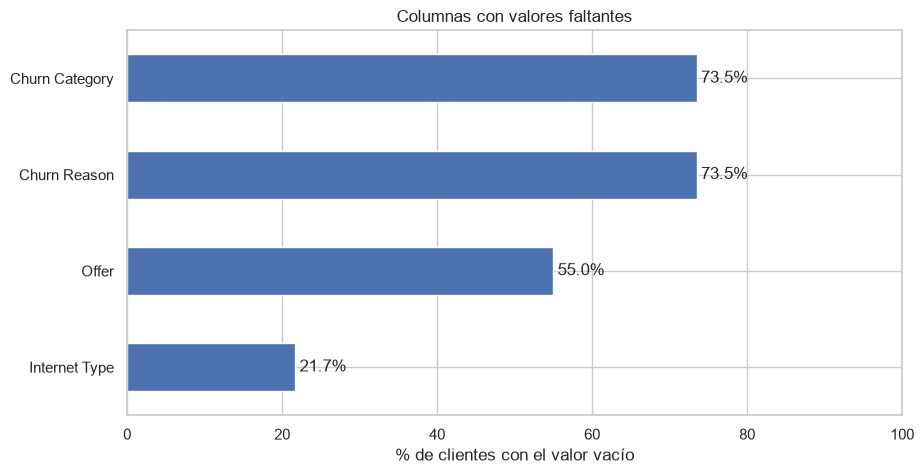

In [17]:
ax = faltantes["porcentaje"].plot.barh(color="#4C72B0")
ax.invert_yaxis()
ax.set_xlabel("% de clientes con el valor vacío")
ax.set_title("Columnas con valores faltantes")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, 100)
plt.show()

### 4.2 ¿Por qué faltan?

Revisamos si los vacíos coinciden con alguna condición del cliente.

In [18]:
# Internet Type vacío vs. si el cliente tiene internet
pd.crosstab(
    clientes["Internet Service"],
    clientes["Internet Type"].isna(),
    rownames=["Internet Service"],
    colnames=["Internet Type vacío"],
)

Internet Type vacío,False,True
Internet Service,,
No,0,1526
Yes,5517,0


In [19]:
# Churn Category / Churn Reason vacíos vs. estado del cliente
pd.crosstab(
    clientes["Customer Status"],
    clientes["Churn Category"].isna(),
    rownames=["Customer Status"],
    colnames=["Churn Category vacío"],
)

Churn Category vacío,False,True
Customer Status,,
Churned,1869,0
Joined,0,454
Stayed,0,4720


In [20]:
# Offer: los vacíos son la categoría más frecuente
clientes["Offer"].value_counts(dropna=False)

Offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

### 4.3 Valores vacíos escondidos

A veces un faltante viene como texto vacío o con espacios (`" "`) y `isna()` no
lo detecta. Revisamos todas las columnas de texto.

In [21]:
columnas_texto = clientes.select_dtypes(exclude="number").columns
vacios_texto = clientes[columnas_texto].apply(
    lambda col: col.astype(str).str.strip().eq("").sum()
)
vacios_texto[vacios_texto > 0]

Series([], dtype: int64)

### 4.4 Duplicados

- **Por llave:** que un mismo `Customer ID` aparezca más de una vez.
- **Por contenido:** dos filas idénticas en todo excepto los identificadores
  (podría ser el mismo cliente registrado dos veces con otro ID).

In [22]:
columnas_id = ["Customer ID", "Location ID", "Service ID", "Status ID"]

pd.Series(
    {
        "Customer ID duplicados": clientes["Customer ID"].duplicated().sum(),
        "filas idénticas (sin contar IDs)": clientes.drop(columns=columnas_id)
        .duplicated()
        .sum(),
    }
)

Customer ID duplicados              0
filas idénticas (sin contar IDs)    0
dtype: int64

### 4.5 Consistencia entre columnas

Columnas que se derivan de otras o que dependen de un servicio deberían cuadrar.
Cada regla cuenta cuántos clientes **no** la cumplen.

In [23]:
EDAD_SENIOR = 65
EDAD_MENOR_30 = 30
TOLERANCIA_DOLARES = 0.01

sin_internet = clientes["Internet Service"] == "No"
sin_telefono = clientes["Phone Service"] == "No"
servicios_internet = [
    "Online Security",
    "Online Backup",
    "Device Protection Plan",
    "Premium Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Streaming Music",
    "Unlimited Data",
]
ingreso_calculado = (
    clientes["Total Charges"]
    - clientes["Total Refunds"]
    + clientes["Total Extra Data Charges"]
    + clientes["Total Long Distance Charges"]
)

reglas = {
    "Senior Citizen = Age >= 65": (clientes["Age"] >= EDAD_SENIOR)
    != (clientes["Senior Citizen"] == "Yes"),
    "Under 30 = Age < 30": (clientes["Age"] < EDAD_MENOR_30)
    != (clientes["Under 30"] == "Yes"),
    "Dependents = Number of Dependents > 0": (clientes["Number of Dependents"] > 0)
    != (clientes["Dependents"] == "Yes"),
    "Referred a Friend = Number of Referrals > 0": (clientes["Number of Referrals"] > 0)
    != (clientes["Referred a Friend"] == "Yes"),
    "Sin internet -> sin servicios de internet": sin_internet
    & (clientes[servicios_internet] == "Yes").any(axis=1),
    "Sin internet -> 0 GB de descarga": sin_internet
    & (clientes["Avg Monthly GB Download"] > 0),
    "Sin teléfono -> sin líneas múltiples": sin_telefono
    & (clientes["Multiple Lines"] == "Yes"),
    "Sin teléfono -> 0 cargos de larga distancia": sin_telefono
    & (clientes["Avg Monthly Long Distance Charges"] > 0),
    "Total Revenue = cargos - reembolsos + extras": (
        ingreso_calculado - clientes["Total Revenue"]
    ).abs()
    > TOLERANCIA_DOLARES,
}
pd.Series({regla: incumple.sum() for regla, incumple in reglas.items()}).to_frame(
    "clientes que no cumplen"
)

,clientes que no cumplen
Senior Citizen = Age >= 65,0
Under 30 = Age < 30,0
Dependents = Number of Dependents > 0,0
Referred a Friend = Number of Referrals > 0,0
Sin internet -> sin servicios de internet,0
Sin internet -> 0 GB de descarga,0
Sin teléfono -> sin líneas múltiples,0
Sin teléfono -> 0 cargos de larga distancia,0
Total Revenue = cargos - reembolsos + extras,0


### Observaciones y decisiones

1. **Ningún faltante es un dato perdido; todos tienen explicación de negocio:**

   | Columna | Faltantes | Motivo | Decisión para la limpieza |
   |---|---|---|---|
   | `Offer` | 3,877 (55 %) | El cliente no aceptó ninguna oferta | Reemplazar por la categoría `"None"` |
   | `Internet Type` | 1,526 (21.7 %) | Exactamente los clientes **sin internet** | Reemplazar por `"No Internet"` |
   | `Churn Category`, `Churn Reason` | 5,174 (73.5 %) | Solo existen para clientes que **se fueron** | Excluir: es información posterior al churn (fuga de datos) |

   Por eso **no imputamos con media o moda**: eso inventaría información que el
   cliente no tiene. Lo correcto es tratar el vacío como su propia categoría.

2. **No hay vacíos escondidos** (textos vacíos o con espacios).
3. **No hay duplicados**, ni por `Customer ID` ni por contenido. No se elimina
   ninguna fila, pero el pipeline validará esto para detectar cambios en los datos.
4. **Todas las reglas de consistencia se cumplen:** las columnas derivadas
   cuadran con su origen y los clientes sin internet o sin teléfono no tienen
   cargos ni servicios asociados. Esto confirma que las columnas redundantes de
   la sección 2 se pueden eliminar sin perder información.
5. A diferencia de la versión original de IBM, `Total Charges` no tiene vacíos
   (allí aparecían para clientes con 0 meses de antigüedad).

## 5. Variable objetivo y fuga de datos

**Variable objetivo:** `Churn Value` (1 = el cliente canceló en el trimestre,
0 = sigue activo).

Además de entender cómo se distribuye, revisamos qué columnas **no se pueden
usar como predictores** porque contienen información que solo existe *después*
de que el cliente se fue. Si el modelo las usa, sus métricas se ven excelentes
en el notebook pero no sirven en la vida real: cuando el equipo de retención
quiera predecir, esa información todavía no existe. Esto se llama **fuga de
datos (*data leakage*)**.

### 5.1 Distribución de la variable objetivo

In [24]:
conteo_churn = (
    clientes["Churn Value"]
    .map({0: "Se queda", 1: "Se va (churn)"})
    .value_counts()
    .to_frame("clientes")
    .assign(
        porcentaje=lambda df: (df["clientes"] / df["clientes"].sum() * 100).round(1)
    )
)
conteo_churn

,clientes,porcentaje
Churn Value,,
Se queda,5174,73.5
Se va (churn),1869,26.5


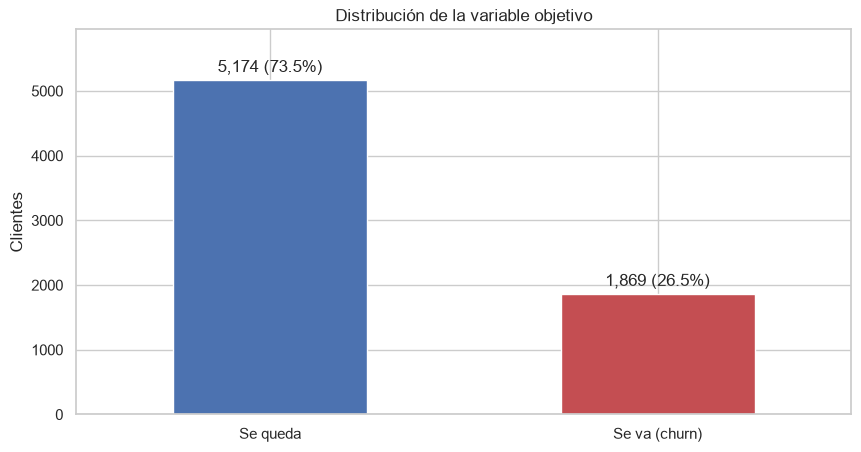

In [25]:
ax = conteo_churn["clientes"].plot.bar(color=["#4C72B0", "#C44E52"], rot=0)
ax.bar_label(
    ax.containers[0],
    labels=[
        f"{n:,} ({p}%)"
        for n, p in zip(conteo_churn["clientes"], conteo_churn["porcentaje"])
    ],
    padding=3,
)
ax.set_ylabel("Clientes")
ax.set_xlabel("")
ax.set_title("Distribución de la variable objetivo")
ax.set_ylim(0, conteo_churn["clientes"].max() * 1.15)
plt.show()

### 5.2 `Customer Status` frente a la variable objetivo

`Customer Status` tiene tres valores. Revisamos cómo se relaciona con
`Churn Value` y con la antigüedad del cliente.

In [26]:
pd.crosstab(clientes["Customer Status"], clientes["Churn Value"], margins=True)

Churn Value,0,1,All
Customer Status,,,
Churned,0,1869,1869
Joined,454,0,454
Stayed,4720,0,4720
All,5174,1869,7043


In [27]:
clientes.groupby("Customer Status")["Tenure in Months"].agg(["min", "median", "max"])

,min,median,max
Customer Status,,,
Churned,1,10.0,72
Joined,1,1.0,3
Stayed,4,42.0,72


### 5.3 Columnas con fuga de datos

Una forma rápida de detectar fuga es medir **qué tan bien separa cada columna,
por sí sola, a los clientes que se van de los que se quedan**. Usamos el AUC
(0.5 = no separa nada, 1.0 = separa perfecto). Una sola variable con un AUC
cercano a 1 es sospechosa: en un problema real ninguna variable debería
predecir casi perfecto por sí misma.

In [28]:
from sklearn.metrics import roc_auc_score

columnas_numericas = (
    clientes.select_dtypes("number")
    .drop(columns=["Churn Value", "Count", "Zip Code", "Latitude", "Longitude"])
    .columns
)


def auc_individual(columna: pd.Series, objetivo: pd.Series) -> float:
    """AUC de una sola variable, sin importar si se relaciona en positivo o negativo."""
    auc = roc_auc_score(objetivo, columna)
    return max(auc, 1 - auc)


poder_separacion = (
    pd.Series(
        {
            col: auc_individual(clientes[col], clientes["Churn Value"])
            for col in columnas_numericas
        }
    )
    .sort_values(ascending=False)
    .round(3)
)
poder_separacion.to_frame("AUC individual").head(10)

,AUC individual
Satisfaction Score,0.950
Churn Score,0.943
Tenure in Months,0.741
Total Revenue,0.672
Total Long Distance Charges,0.657
Total Charges,0.651
Number of Referrals,0.639
Monthly Charge,0.621
Number of Dependents,0.619
CLTV,0.581


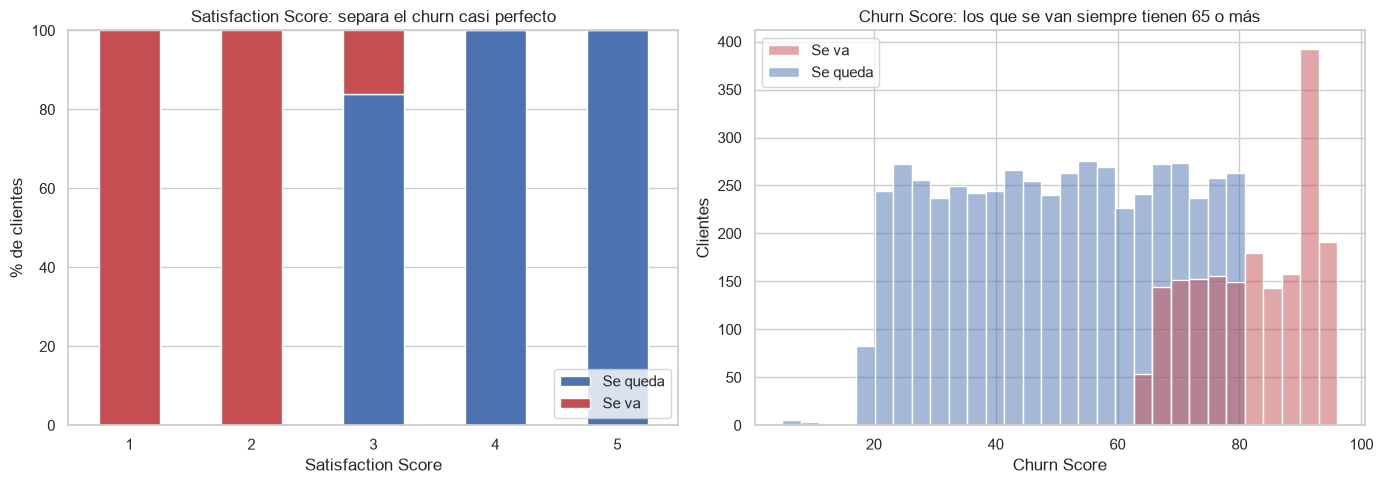

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Satisfaction Score: % de churn por nivel
(
    pd.crosstab(
        clientes["Satisfaction Score"], clientes["Churn Value"], normalize="index"
    )
    .mul(100)
    .rename(columns={0: "Se queda", 1: "Se va"})
    .plot.bar(stacked=True, color=["#4C72B0", "#C44E52"], rot=0, ax=axes[0])
)
axes[0].set_ylabel("% de clientes")
axes[0].set_title("Satisfaction Score: separa el churn casi perfecto")
axes[0].legend(loc="lower right")

# Churn Score: distribución por grupo
sns.histplot(
    data=clientes,
    x="Churn Score",
    hue=clientes["Churn Value"].map({0: "Se queda", 1: "Se va"}),
    palette={"Se queda": "#4C72B0", "Se va": "#C44E52"},
    bins=30,
    ax=axes[1],
)
axes[1].set_title("Churn Score: los que se van siempre tienen 65 o más")
axes[1].set_ylabel("Clientes")
axes[1].get_legend().set_title("")

plt.tight_layout()
plt.show()

In [30]:
pd.crosstab(clientes["Satisfaction Score"], clientes["Churn Value"])

Churn Value,0,1
Satisfaction Score,,
1,0,922
2,0,518
3,2236,429
4,1789,0
5,1149,0


### Observaciones y decisiones

1. **Clases desbalanceadas: 26.5 % churn y 73.5 % no churn.** No es un
   desbalance extremo, pero implica que:
   - la *accuracy* engaña: un modelo que diga "nadie se va" acierta el 73.5 %;
   - usaremos **recall, precisión, F1 y PR-AUC** (definidas en el problema de negocio);
   - la división train/test será **estratificada** para conservar la proporción;
   - evaluaremos `class_weight="balanced"` o ajuste del umbral.

2. **`Customer Status`:** *Churned* equivale exactamente a `Churn Value = 1`.
   *Joined* (454 clientes nuevos, de 1 a 3 meses) y *Stayed* son clientes activos
   (`Churn Value = 0`). Los clientes nuevos **se conservan**: son clientes que el
   equipo de retención también debe evaluar.

3. **Columnas excluidas como predictores por fuga de datos:**

   | Columna | Evidencia | Motivo |
   |---|---|---|
   | `Customer Status` | Igual al objetivo | Es la misma respuesta con otro nombre |
   | `Churn Label` | Igual al objetivo | Versión Sí/No de `Churn Value` |
   | `Churn Category`, `Churn Reason` | Solo existen si el cliente se fue | Se registran al cancelar |
   | `Churn Score` | AUC 0.94; todos los churners tienen ≥ 65 | Es la predicción de otro modelo de IBM |
   | `Satisfaction Score` | AUC 0.95; 1–2 = siempre se va, 4–5 = nunca se va | Probablemente se registra al cancelar o se construyó con el resultado; no es confiable antes del churn |
   | `CLTV` | AUC 0.58 | Valor estimado por IBM; se usará **solo para estimar el impacto económico** |

4. **Las demás variables tienen un poder de separación razonable** (AUC entre
   0.5 y 0.75). La más fuerte es `Tenure in Months` (0.74): los clientes nuevos
   se van más. Esto se analiza en la siguiente sección.

`Churn Category` y `Churn Reason` no sirven para predecir, pero sí para el
**reporte de negocio**: explican *por qué* se van los clientes (la competencia
es el motivo principal).